## M1:
1. Anota qué campos aparecen en la primera respuesta y no en la segunda.
raw_score y threshold_config desaparecen de la respuesta pública porque son datos internos.
2. Explica en una frase por qué /v1/scores/filtered tampoco los devuelve, aunque la función devuelve un dict con todos ellos.
Aunque la función devuelve un dict con todos los campos, FastAPI utiliza response_model=PublicScore para filtrar los datos y excluir automáticamente los campos que no están declarados en el modelo público, como raw_score y threshold_config.
3. En /docs, abre el esquema PublicScore: ¿aparece is_reliable?
Si


## M2:
1. Rellena una tabla con status, error.code y error.fields de cada caso.


| Petición | Status | error.code | error.fields |
|---|---|---|---|
| `age: 30, income: 1000` | 200 | No existe | No existe |
| `age: "treinta", income: 1000` | 422 | `validation_error` | `age`: debe ser un entero válido |
| `age: 30` sin `income` | 422 | `validation_error` | `income`: Field required |
| GET `/v1/nada` | 404 | `not_found` | No aparece |
| GET `/v1/boom` | 500 | `internal_error` | No aparece |


2. ¿Qué devolvería FastAPI en el segundo caso si borraras handle_validation? Pruébalo comentando el decorador y restáuralo después

Si eliminamos el decorador de handle_validation, FastAPI devuelve un error HTTP 422 con su formato predeterminado, utilizando la clave detail en lugar de error.

La respuesta incluye el tipo de error (int_parsing), su ubicación (body.age), un mensaje explicativo y el valor incorrecto recibido ("treinta").

Esto demuestra que handle_validation sirve para personalizar y unificar el formato de los errores de validación de la API.

## M3
1. Localiza en /openapi.json dónde terminan summary, el docstring y responses de create_score.

summary: aparece como "Calcular el score de riesgo".

Docstring: "description": "Calcula la probabilidad de impago de un cliente.\n\n- `age` entre 18 y 100, `income` mayor que 0.\n- El score es docente: **no** es una decisión de crédito."

responses: documenta las posibles respuestas HTTP: 200 (score y versión del modelo), 422 (entrada fuera de contrato) y 503 (modelo no disponible).


2. Ejecuta el ejemplo minor desde Swagger con «Try it out».
La API ha devuelto un error HTTP 422 porque el campo age tiene un valor de 16, inferior al mínimo permitido de 18 años. FastAPI detecta automáticamente que los datos no cumplen las restricciones definidas en el modelo de entrada.
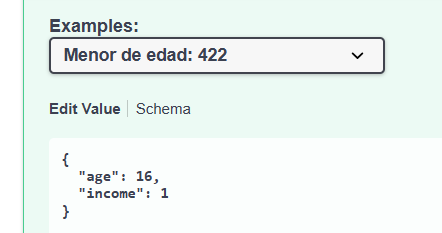
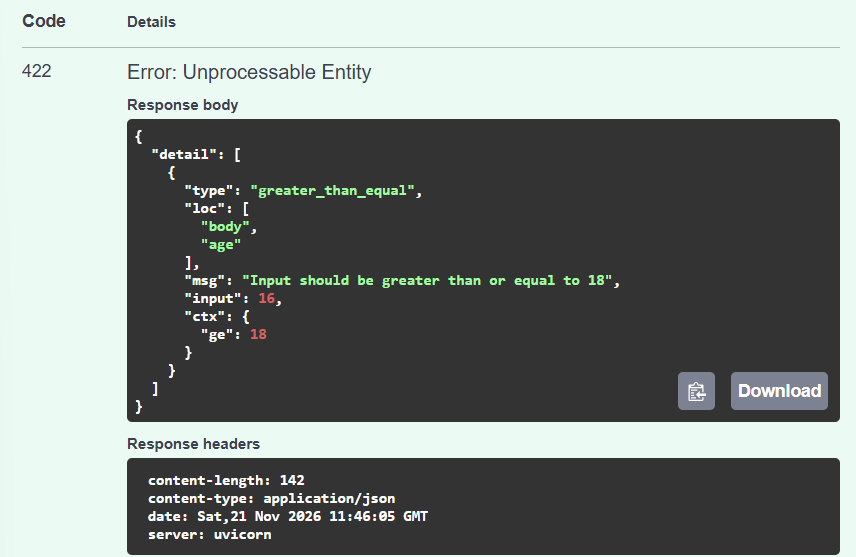

3. Añade un tercer ejemplo no_income sin el campo income y comprueba que aparece en el desplegable
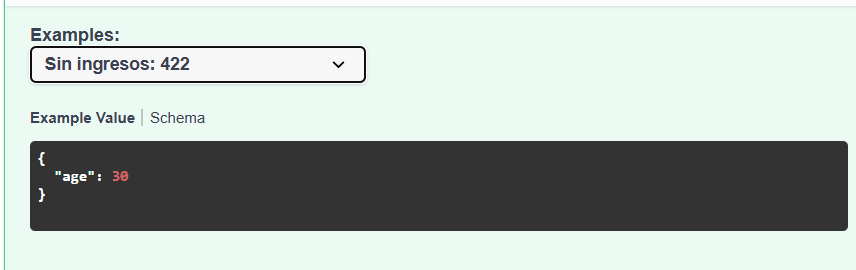


## M4
1. Ejecuta uv run pytest -q y localiza el test que usa dependency_overrides.
El test que usa dependency_overrides es:
test_dependency_override_simulates_unavailable_model.

Este test sustituye la dependencia get_model por un modelo simulado con ready = False. Después realiza una petición POST con datos válidos y comprueba que la API devuelve HTTP 503 con el código model_unavailable.

2. Elimina temporalmente raise_server_exceptions=False del fixture errors_client y vuelve a ejecutar. Explica qué cambia.
Sin raise_server_exceptions = False
TestClient utiliza su comportamiento predeterminado (TRUE) y te pasa directamente la excepción de Pyhton
RuntimeError: password=TU_SECRETO in /etc/app.conf 
y el test se interrumpe antes de comprobar la respuesta HTTP 500.

Por eso el resultado ha sido 1 failed, 8 passed.
Con raise_server_exceptions=False, el test puede recibir y comprobar la respuesta HTTP 500 sin interrumpirse por la excepción.

3. Escribe un test nuevo que compruebe que income: 0 devuelve 422 con fields[0].field == "income".
He puesto esto :
def test_income_zero_returns_422(errors_client: TestClient) -> None:
    response = errors_client.post(
        "/v1/scores",
        json={"age": 30, "income": 0},
    )

    assert response.status_code == 422
    assert response.json()["error"]["fields"][0]["field"] == "income"